# 04 - Hedging NVDA with MNQ futures instead of shorting QQQ

**TL;DR** (data through 2026-11-20; MNQ margin assumed, CME site unreachable)
- One MNQ = \$2 x NDX = **\$50.1k** of Nasdaq-100. Hedge ratio (shrunk beta to NDX
  futures) = **1.47**, so one contract hedges about **\$34k of NVDA**.
- **Recommended: 1 MNQ against \$32-34k NVDA.** At \$32k the effective hedge is 1.56
  (\$3k over-hedged) and monthly 99% VaR is about \$9.8k. Every reasonable `h` estimate
  (1.18-1.66) still rounds to 1 contract.
- **Capital roughly halves:** about \$19.6k (NVDA on Reg T plus ~\$3.6k futures margin)
  vs \$39.5k for the QQQ short. There are no short proceeds to lock up and no borrow fee.
- **Backtest 2020-2026, \$32k NVDA:** MNQ book Sharpe 0.95, +\$10.2k a year, max drawdown
  \$10.1k. The QQQ book (full rebate) had Sharpe 0.90, +\$9.4k, max drawdown \$13.1k.
  The structural edge is small (+\$106 a year: borrow fee avoided less QQQ's expense
  ratio). Most of the difference is luck from integer rounding.
- **Against a broker that pays no rebate**, MNQ wins by about \$2.4k a year. With half
  the equity, a monthly 99% loss (~\$10k) is ~50% of the account: keep a cushion.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

from nvai import hedge as hg
from nvai.config import FIGURES
from nvai.data import load

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 150, "display.float_format", lambda v: f"{v:,.2f}")
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK2, GRID = "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK2,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "legend.frameon": False, "font.size": 9,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})


def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png")
    plt.show()


# Assumptions (edit here)
MULT = 2.0                 # MNQ: $2 x Nasdaq-100 index
MM = 3_300                 # $ maintenance margin per MNQ (ASSUMED, see section 1)
IM = 1.10 * MM             # CME initial = 110% of maintenance for speculators
QQQ_ER = 0.0020            # QQQ expense ratio: NDX total return = QQQ TR + 0.20%/yr
TICK = 0.25 * MULT         # 1 tick = 0.25 index points = $0.50 per MNQ
COMM = 1.00                # $ per contract per side
L_TARGET, VAR_TARGET = 32_000, 10_000
TCOST_STOCK = 0.0010       # 10 bp per side on NVDA / QQQ trades (as in 03)
ANN, M = 252, 21

ret = load.returns()[["NVDA", "QQQ"]].dropna()
rf = load.risk_free().reindex(ret.index).ffill()
fee = load.borrow_fees(fill_default=True)["QQQ"].reindex(ret.index).ffill()
fut = pd.read_parquet(load.raw_dir("free") / "ndx_futures.parquet").set_index("date")
ndx = fut["NDX"].reindex(ret.index).ffill()

xn = ret.NVDA - rf                                   # NVDA excess return
f = ret.QQQ + QQQ_ER / ANN - rf                      # fair-value NDX futures return
xq = ret.QQQ - rf                                    # QQQ excess return

## 1. One MNQ contract today

Notional = \$2 x the Nasdaq-100. Margin: CME's margin pages and the broker page I tried
could not be reached from here (2026-11-22). **The margin below is an assumption**
(about 6.5% of notional, consistent with recent NQ/MNQ levels). Check your broker's
number before trading.

In [2]:
last = ndx.index[-1]
C_now = MULT * ndx.iat[-1]
mnq_last = fut["MNQ"].dropna()
mnq_last = mnq_last[mnq_last.index <= last].iat[-1]
expiry = pd.Timestamp("2026-12-18")                  # Dec-26 MNQ, third Friday
tau = (expiry - last).days / 365
basis = mnq_last / ndx.iat[-1] - 1
pd.Series({
    "NDX close": f"{ndx.iat[-1]:,.2f} ({last.date()})",
    "MNQ contract notional": f"${C_now:,.0f}",
    "MNQ=F close (Dec-26)": f"{mnq_last:,.2f}",
    "basis F/S - 1": f"{100 * basis:.2f}%  (implied r - q ~ {100 * np.log1p(basis) / tau:.1f}%/yr;"
                     " close times differ, so rough)",
    "initial / maintenance margin (assumed)": f"${IM:,.0f} / ${MM:,.0f}",
}, name="value").to_frame()

,value
NDX close,"25,028.98 (2026-11-20)"
MNQ contract notional,"$50,058"
MNQ=F close (Dec-26),"25,126.50"
basis F/S - 1,0.39% (implied r - q ~ 5.1%/yr; close times d...
initial / maintenance margin (assumed),"$3,630 / $3,300"


**Synthetic vs actual futures.** A fair-value future returns the NDX total return minus
the T-bill rate each day. Below I check that against yfinance's continuous NQ=F. Days
where the two differ by more than 1% are treated as roll jumps and dropped.

In [3]:
nq = fut["NQ"].reindex(ret.index).pct_change()
both = pd.concat({"synthetic": f, "NQ=F": nq}, axis=1).dropna()
roll = (both["NQ=F"] - both["synthetic"]).abs() > 0.01
clean = both[~roll]
pd.Series({
    "days compared": len(both), "roll-jump days dropped": int(roll.sum()),
    "correlation (clean days)": clean.corr().iat[0, 1],
    "mean NQ=F minus synthetic, bp/yr": 1e4 * ANN * (clean["NQ=F"] - clean["synthetic"]).mean(),
    "tracking vol, %/yr": 100 * np.sqrt(ANN) * (clean["NQ=F"] - clean["synthetic"]).std(),
}, name="value").to_frame()

,value
days compared,"1,983.00"
roll-jump days dropped,35.00
correlation (clean days),1.00
"mean NQ=F minus synthetic, bp/yr",-38.87
"tracking vol, %/yr",2.19


The leftover tracking vol comes from close-time mismatch (futures settle at 4:15pm,
the index at 4pm), not real slippage. It averages out. Real futures returned about
0.4%/yr less than fair value, so a short MNQ earned a bit more than the T-bill-based
model assumes (a rough number: roll days are dropped). The backtest ignores this.

## 2. Hedge ratio vs NDX futures

In [4]:
b63 = hg.rolling_beta(xn, f, 63)
b252 = hg.rolling_beta(xn, f, 252)
b_full = xn.expanding(252).cov(f) / f.expanding(252).var()
ewma = hg.ewma_beta(xn, f, 63)
shrunk = 0.5 * b252 + 0.5 * b_full
h_shrunk_m = hg.hold_monthly(shrunk)
H = shrunk.iat[-1]
pd.Series({"trailing 63d": b63.iat[-1], "trailing 252d": b252.iat[-1],
           "EWMA (63d half-life)": ewma.iat[-1], "full sample": b_full.iat[-1],
           "shrunk 50/50 (recommended)": H}, name="beta").to_frame().T

,trailing 63d,trailing 252d,EWMA (63d half-life),full sample,shrunk 50/50 (recommended)
beta,1.38,1.28,1.32,1.66,1.47


**Recommended `h` = the shrunk beta**, the same rule as in 03. The trailing year
(about 1.27) reflects NVDA's 2026 decoupling. The full sample (about 1.67) reflects
2019-2025. Shrinking splits the difference and moves slowly.

## 3. Is `h` robust? (a check, not a new rule)

In [5]:
try:
    import yfinance as yf
    ed = yf.Ticker("NVDA").get_earnings_dates(limit=40).index
    earn = pd.DatetimeIndex(ed.tz_localize(None).normalize())
    earn_days = pd.DatetimeIndex([ret.index[ret.index > d][0] for d in earn
                                  if (ret.index > d).any()])
except Exception:  # noqa: BLE001 - earnings dates are optional
    earn_days = pd.DatetimeIndex([])


def ols_beta(y, x):
    d = pd.concat([y, x], axis=1).dropna()
    return np.polyfit(d.iloc[:, 1], d.iloc[:, 0], 1)[0]


def trail(s, n):
    return s.iloc[-n:]


def weekly(s):
    return (1 + s).resample("W-FRI").prod() - 1


y252, x252 = trail(xn, 252), trail(f, 252)
rlm = sm.RLM(y252, sm.add_constant(x252), M=sm.robust.norms.HuberT()).fit().params.iloc[1]
lo_y, hi_y = y252.quantile([0.01, 0.99])
lo_x, hi_x = x252.quantile([0.01, 0.99])
keep = ~y252.index.isin(earn_days)
variants = pd.Series({
    "daily OLS, 126d": ols_beta(trail(xn, 126), trail(f, 126)),
    "daily OLS, 252d": ols_beta(y252, x252),
    "daily OLS, 504d": ols_beta(trail(xn, 504), trail(f, 504)),
    "weekly OLS, 252d (52 wks)": ols_beta(weekly(trail(ret.NVDA, 252)) - weekly(trail(rf, 252)),
                                          weekly(trail(f + rf, 252)) - weekly(trail(rf, 252))),
    "weekly OLS, 504d (104 wks)": ols_beta(weekly(trail(ret.NVDA, 504)) - weekly(trail(rf, 504)),
                                           weekly(trail(f + rf, 504)) - weekly(trail(rf, 504))),
    "daily Huber (robust), 252d": rlm,
    "daily winsorized 1/99%, 252d": ols_beta(y252.clip(lo_y, hi_y), x252.clip(lo_x, hi_x)),
    f"daily OLS ex earnings ({(~keep).sum()} days), 252d": ols_beta(y252[keep], x252[keep]),
    "full sample": b_full.iat[-1],
    "shrunk 50/50 (recommended)": H,
}, name="beta")

# block bootstrap of the trailing-252d piece of the shrunk beta (21-day blocks)
rng = np.random.default_rng(0)
Y, X = y252.to_numpy(), x252.to_numpy()
starts = np.arange(0, 252 - M + 1)
boot = []
for _ in range(2000):
    idx = np.concatenate([np.arange(s, s + M) for s in rng.choice(starts, 12)])
    boot.append(0.5 * np.polyfit(X[idx], Y[idx], 1)[0] + 0.5 * b_full.iat[-1])
ci = np.percentile(boot, [5, 95])
N_at = {k: H_ * L_TARGET / C_now for k, H_ in [("low", ci[0]), ("mid", H), ("high", ci[1])]}
print(f"shrunk h = {H:.2f}, bootstrap 90% CI [{ci[0]:.2f}, {ci[1]:.2f}]")
print(f"contracts needed for ${L_TARGET / 1e3:.0f}k NVDA: {N_at['low']:.2f} to {N_at['high']:.2f} "
      f"(point {N_at['mid']:.2f}); NVDA per contract ${C_now / ci[1]:,.0f} to ${C_now / ci[0]:,.0f}")
variants.to_frame()

shrunk h = 1.47, bootstrap 90% CI [1.39, 1.53]
contracts needed for $32k NVDA: 0.89 to 0.98 (point 0.94); NVDA per contract $32,813 to $36,025


,beta
"daily OLS, 126d",1.23
"daily OLS, 252d",1.28
"daily OLS, 504d",1.49
"weekly OLS, 252d (52 wks)",1.28
"weekly OLS, 504d (104 wks)",1.48
"daily Huber (robust), 252d",1.24
"daily winsorized 1/99%, 252d",1.18
"daily OLS ex earnings (5 days), 252d",1.25
full sample,1.66
shrunk 50/50 (recommended),1.47


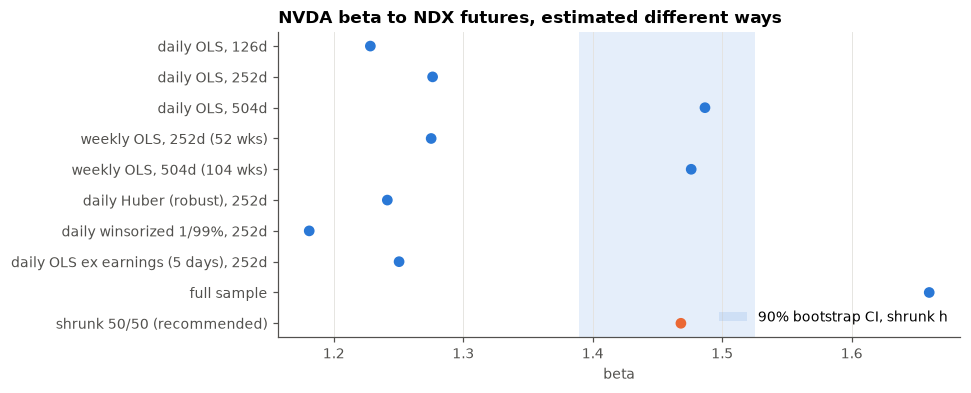

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.6))
v = variants.iloc[::-1]
ax.axvspan(*ci, color=PALETTE[0], alpha=0.12, lw=0, label="90% bootstrap CI, shrunk h")
ax.scatter(v.values, v.index, color=[PALETTE[1] if "shrunk" in k else PALETTE[0]
                                     for k in v.index], s=36, zorder=3)
ax.set_title("NVDA beta to NDX futures, estimated different ways")
ax.set_xlabel("beta")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
save(fig, "04_beta_robustness")

Takeaway: one-year estimates cluster at 1.2-1.3 whatever the method (robust,
winsorized, weekly, ex earnings). Two-year and full-sample estimates are 1.5-1.7. The
window matters, the method does not. For \$32k of NVDA, the whole 1.18-1.66 range means
0.75-1.06 contracts, so **one MNQ either way: rounding swamps the uncertainty in `h`**.

## 4. Sizing in whole contracts

In [7]:
u_unit = xn - H * f                                  # book return per $1 NVDA at h
sd = hg.ewma_vol(u_unit.dropna()).iat[-1]
hist_m = hg.hist_var(u_unit.dropna().rolling(M).sum())
rows = []
for N in [1, 2, 3, 4]:
    L_ = N * C_now / H
    rows.append({"MNQ": N, "NVDA long L": L_, "1d VaR (EWMA)": hg.Z99 * sd * L_,
                 "monthly VaR (EWMA x sqrt21)": hg.Z99 * sd * np.sqrt(M) * L_,
                 "monthly VaR (historical)": hist_m * L_,
                 "futures IM": N * IM, "capital, NVDA Reg T": 0.5 * L_ + N * IM,
                 "capital, NVDA outright": L_ + N * IM})
SZ = pd.DataFrame(rows).set_index("MNQ")
N_rec = int((SZ["monthly VaR (EWMA x sqrt21)"] - VAR_TARGET).abs().idxmin())
SZ["closest to $10k"] = np.where(SZ.index == N_rec, "<--", "")
SZ.style.format({c: "{:,.0f}" for c in SZ.columns if c != "closest to $10k"})

,NVDA long L,1d VaR (EWMA),monthly VaR (EWMA x sqrt21),monthly VaR (historical),futures IM,"capital, NVDA Reg T","capital, NVDA outright",closest to $10k
MNQ,,,,,,,,
1,"34,097","2,294","10,514","5,667","3,630","20,678","37,727",<--
2,"68,194","4,589","21,029","11,333","7,260","41,357","75,454",
3,"102,291","6,883","31,543","17,000","10,890","62,035","113,181",
4,"136,388","9,178","42,058","22,666","14,520","82,714","150,908",


**The other way round: \$32k of NVDA.** It needs a fractional number of contracts.
Rounding leaves some NDX exposure unhedged or over-hedged.

In [8]:
N_frac = H * L_TARGET / C_now
N_round = max(1, round(N_frac))
resid_beta = N_round * C_now - H * L_TARGET                # + = extra short NDX
u32 = xn - (N_round * C_now / L_TARGET) * f
pd.Series({
    "contracts needed (h x L / notional)": f"{N_frac:.2f}",
    "rounded": N_round,
    "NDX hedge $ vs ideal": f"{resid_beta:+,.0f}  ({'over' if resid_beta > 0 else 'under'}-hedged)",
    "effective h": f"{N_round * C_now / L_TARGET:.2f} (vs {H:.2f})",
    "monthly VaR (EWMA)": f"${hg.Z99 * hg.ewma_vol(u32.dropna()).iat[-1] * np.sqrt(M) * L_TARGET:,.0f}",
    "capital: NVDA Reg T + IM": f"${0.5 * L_TARGET + N_round * IM:,.0f}",
    "capital: NVDA outright + IM": f"${L_TARGET + N_round * IM:,.0f}",
}, name="$32k NVDA").to_frame()

,$32k NVDA
contracts needed (h x L / notional),0.94
rounded,1
NDX hedge $ vs ideal,"+3,079 (over-hedged)"
effective h,1.56 (vs 1.47)
monthly VaR (EWMA),"$9,842"
capital: NVDA Reg T + IM,"$19,630"
capital: NVDA outright + IM,"$35,630"


No short proceeds and no borrow fee. The futures price already includes financing at
about the T-bill rate minus the index dividend yield.

## 5. Backtest 2020 to now

- **A, fixed contracts:** hold `N` MNQ (the row nearest \$10k VaR) and reset NVDA monthly
  to `N x notional / h`.
- **B, fixed \$32k:** NVDA reset to \$32k monthly, with
  `N = round(h x 32k / notional)` (at least 1).

Futures P&L: `N x $2 x change in F`, using fair-value futures. Costs: \$1 a side per
contract plus 1 tick per trade. A quarterly roll (Mar/Jun/Sep/Dec) costs 2 sides plus
1 tick, charged in the roll month. NVDA trades pay 10 bp. The QQQ book from 03 at the
same `L` is shown alongside (h fractional, Markit fee, full rebate, 10 bp a side).
Returns are over T-bills.

In [9]:
C_t = (MULT * ndx).shift(1)
h_m = h_shrunk_m.dropna()
start = h_m.index[0]
mstart = h_m.groupby(h_m.index.to_period("M")).head(1).index


def futures_book(N_month, L_month):
    """N_month, L_month: Series on month-start days. Returns backtest DataFrame + N path."""
    N_d = N_month.reindex(h_m.index).ffill()
    L_d = L_month.reindex(h_m.index).ffill()
    S_d = N_d * C_t.reindex(h_m.index)
    Ns = {d: int(N_month.loc[d]) for d in mstart}
    keys = list(Ns)

    def cost(pL, pS, tL, tS, d):
        i = keys.index(d)
        n_new, n_old = Ns[d], (Ns[keys[i - 1]] if i else 0)
        c = abs(n_new - n_old) * (COMM + TICK) + TCOST_STOCK * abs(tL - pL)
        if d.month in (3, 6, 9, 12) and i:
            c += min(n_new, n_old) * (2 * COMM + TICK)       # roll the held contracts
        return c
    return hg.monthly_reset_backtest(xn, ret.NVDA, f, f, L_d, S_d, cost)


def qqq_book(L_month):
    L_d = L_month.reindex(h_m.index).ffill()
    df = hg.monthly_reset_backtest(
        xn, ret.NVDA, xq + fee / ANN, ret.QQQ, L_d, h_m * L_d,
        lambda pL, pS, tL, tS, d: TCOST_STOCK * (abs(tL - pL) + abs(tS - pS)))
    df["pnl_norebate"] = df.pnl - 1.5 * df.short * rf.loc[df.index]
    return df


Cm, hm = C_t.loc[mstart], h_m.loc[mstart]
N_A = pd.Series(N_rec, index=mstart)
L_A = N_A * Cm / hm
L_B = pd.Series(float(L_TARGET), index=mstart)
N_B = (hm * L_TARGET / Cm).round().clip(lower=1).astype(int)

bt = {"A: MNQ fixed N": futures_book(N_A, L_A), "A: QQQ same L": qqq_book(L_A),
      "B: MNQ $32k": futures_book(N_B, L_B), "B: QQQ $32k": qqq_book(L_B)}
L_A_now = N_rec * C_now / H
eq = {"A: MNQ fixed N": 0.5 * L_A_now + N_rec * IM,
      "A: QQQ same L": 0.5 * L_A_now * (1 + H),
      "B: MNQ $32k": 0.5 * L_TARGET + N_round * IM,
      "B: QQQ $32k": 0.5 * L_TARGET * (1 + H)}
PERF = pd.DataFrame({k: hg.perf_stats(v.pnl, eq[k]) for k, v in bt.items()})
PERF["B: QQQ $32k, no rebate"] = hg.perf_stats(bt["B: QQQ $32k"].pnl_norebate,
                                               eq["B: QQQ $32k"])
PERF.loc["equity used for % (Reg T)"] = list(eq.values()) + [eq["B: QQQ $32k"]]
print(f"{start.date()} to {ret.index[-1].date()}; B used N = "
      f"{dict(N_B.value_counts().sort_index())} (months at each N)")
PERF

2020-01-02 to 2026-11-20; B used N = {1: np.int64(21), 2: np.int64(55), 3: np.int64(7)} (months at each N)


,A: MNQ fixed N,A: QQQ same L,B: MNQ $32k,B: QQQ $32k,"B: QQQ $32k, no rebate"
annual P&L $,"4,146.72","4,090.98","10,196.14","9,432.09","7,004.10"
annual % of equity,20.05,9.72,51.94,23.88,17.74
vol $/yr,"6,867.74","6,867.96","10,785.61","10,508.04","10,507.05"
Sharpe,0.60,0.60,0.95,0.90,0.67
Sortino,0.90,0.89,1.50,1.44,1.06
max drawdown $,"-13,496.46","-13,575.79","-10,136.60","-13,100.79","-19,088.04"
max drawdown % equity,-65.27,-32.26,-51.64,-33.18,-48.34
worst day $,"-3,411.95","-3,413.76","-4,500.84","-3,910.74","-3,926.59"
worst day,2026-11-09,2026-11-09,2025-01-27,2025-01-27,2025-01-27
worst month $,"-8,153.90","-8,147.86","-5,579.20","-6,754.44","-6,921.31"


Reg T vs outright NVDA: the \$ P&L is the same, because the margin loan is charged at
the T-bill rate here. Only the equity changes. Outright needs about \$16k more, so the
% return is lower. A real margin loan at T-bill + 1.5% would cost about \$240 a year on
the \$16k loan.

**Where the gap between the two \$32k books comes from** (annual \$, mean, and the
tracking vol it adds):

In [10]:
mq, mf = bt["B: QQQ $32k"], bt["B: MNQ $32k"]
ix = mq.index.intersection(mf.index)
comp = pd.DataFrame({
    "integer rounding (S_fut - S_qqq) x f": -(mf.short - mq.short).loc[ix] * f.loc[ix],
    "QQQ borrow fee avoided": mq.short.loc[ix] * fee.loc[ix] / ANN,
    "QQQ expense ratio (QQQ short gains it)": -mq.short.loc[ix] * QQQ_ER / ANN,
})
comp["trading/roll costs, other"] = (mf.pnl - mq.pnl).loc[ix] - comp.sum(axis=1)
comp["total: MNQ minus QQQ book"] = (mf.pnl - mq.pnl).loc[ix]
gap = pd.DataFrame({"$/yr": ANN * comp.mean(), "tracking vol $/yr": np.sqrt(ANN) * comp.std()})
gap.loc["no-rebate QQQ: extra edge for MNQ"] = [
    ANN * (mq.pnl - mq.pnl_norebate).loc[ix].mean(), np.nan]
gap

,$/yr,tracking vol $/yr
integer rounding (S_fut - S_qqq) x f,634.56,"2,282.64"
QQQ borrow fee avoided,215.08,4.95
QQQ expense ratio (QQQ short gains it),-108.91,0.66
"trading/roll costs, other",23.32,23.93
total: MNQ minus QQQ book,764.04,"2,282.89"
no-rebate QQQ: extra edge for MNQ,"2,427.99",NaN


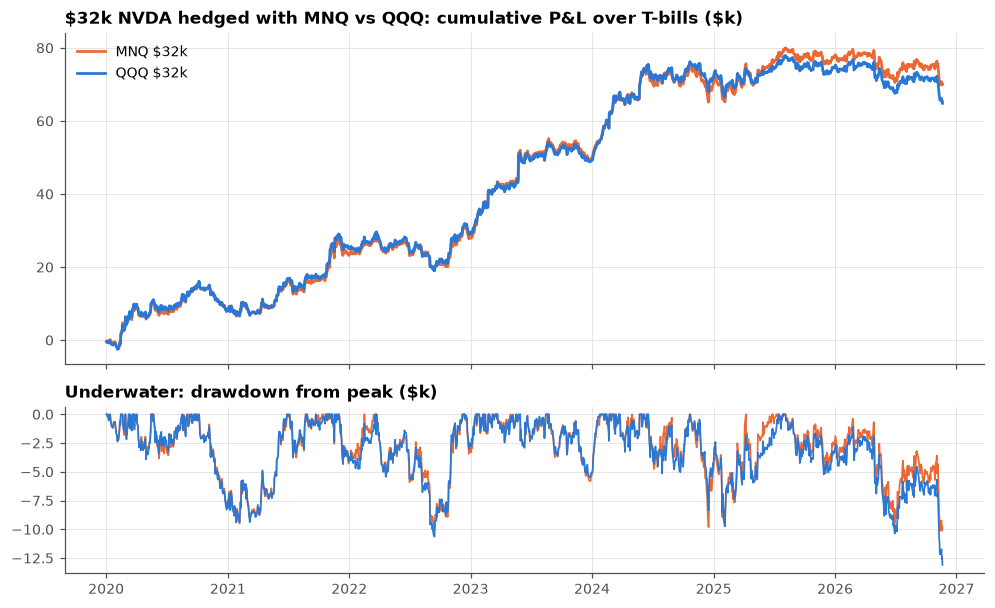

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(9, 5.6), sharex=True,
                         gridspec_kw={"height_ratios": [2, 1]})
for k, c in [("B: MNQ $32k", PALETTE[1]), ("B: QQQ $32k", PALETTE[0])]:
    cum = bt[k].pnl.cumsum()
    axes[0].plot(cum.index, cum / 1e3, color=c, lw=1.8, label=k[3:])
    dd = (cum - cum.cummax()) / 1e3
    axes[1].plot(dd.index, dd, color=c, lw=1.1, label=k[3:])
axes[0].set_title(r"\$32k NVDA hedged with MNQ vs QQQ: cumulative P&L over T-bills (\$k)")
axes[0].legend(loc="upper left")
axes[1].set_title(r"Underwater: drawdown from peak (\$k)")
fig.tight_layout()
save(fig, "04_mnq_vs_qqq")

## 6. Bottom line

For this account size MNQ is the better hedge. It needs half the capital, has no borrow
or rebate risk, and costs a few dollars a quarter to roll. Its only drawback is the
lumpy one-contract size, which leaves the hedge 0-10% off target. Today: **1 MNQ short
against about \$32-34k of NVDA** (h = 1.47 shrunk), funded with about \$20k of equity
plus a \$10k cushion, since a 99% bad month is about \$10k.